\tableofcontents

\newpage

# The Effect of Common Productivity Shock on Misallocation

**Alireza Shirkhodaee**

Graduate School of Management and Economics,

Sharif University of Technology

ar.shirkhodaee@gmail.com

December 2024

# Description
This script analyzes the impact of common productivity shocks on resource misallocation across firms. The study explores how aggregate changes in productivity affect the efficiency with which resources are distributed among heterogeneous firms and industries, using a quantitative approach. The results have implications for understanding economic efficiency and potential policy responses to productivity changes.

# Usage
This code is written in Julia. To execute, make sure you have Julia installed along with all necessary dependencies. Please refer to the instructions below for how to install the required packages.

## Requirements
* Julia version 1.6 or above
* To install dependencies, run the following in Julia REPL:
    `
    using Pkg; Pkg.add(["DataFrames", "CSV", "Plots", "StatsBase", "LinearAlgebra",
    "Statistics", "Distributions", "Interpolations", "LaTeXStrings", "Parameters",
    "Roots", "Optim", "Random"])
    `

## Included Files
* `Model.jl`: Contains the dynamic programming model (DpModel).
* `PolicyCalculation.jl`: Contains the Value Function Iteration (VFI) method to policy functions calculation (PolicyCalc).
* `Simulation.jl`: Contains the time series simulation functions (SimulationTS).
* `Heterogeneous.jl`: Contains functions related to heterogeneous agent analysis (Heter).


# Notes
* This script is part of an ongoing research project. Please consult the author before using it for commercial purposes.
\newpage


# Model Specification

In this section, we propose a model to describe firms' decision-making processes. The model is a dynamic and stochastic partial equilibrium framework that identifies firms' optimal behavior over time, accounting for various frictions in the investment and financing processes. Firms' productivity is divided into two components: a firm-specific component and a common component shared by all firms. The common productivity component represents the macroeconomic conditions that are uniform across firms.

The stochastic processes for productivity are shown below:

$$
a_{it} = z_{it} + m_t
$$

$$
z_{it+1} = \rho_z z_{it} + (1 - \rho_z) \bar{z}_i + \mu_{it+1}^z, \quad \mu_{it}^z \sim N(0, \sigma_{\mu^z}^2)
$$

$$
m_{t+1} = \rho_m m_t + (1 - \rho_m) \bar{m} + \mu_{t+1}^m, \quad \mu_t^m \sim N(0, \sigma_{\mu^m}^2)
$$

Firms face four types of frictions in the investment process. First, the cost of maintaining capital varies across firms and depends on their level of capital, productivity, and firm-specific characteristics. Additionally, firms encounter capital adjustment costs, which are convex functions of investment, as well as relatively irreversible costs associated with changes in capital, which are nonlinear and represent a form of price rigidity. The fourth friction is a constraint on the maximum amount of capital a firm can raise, limiting firms to invest only up to a fixed proportion of their output. This represents a quantity constraint.

The equations of the frictions are given below:

1. Convex Capital Adjustment Cost

$$
    \Phi_A(K_{it+1},K_{it})=\frac{\xi}{2}\left( \frac{K_{it+1}}{K_{it}} -(1-\delta)\right)^2 K_{it}
$$

2. Partially Irreversible Costs of Capital:

$$
\Phi_N =
\begin{cases}
    \phi_n P_{\text{gap}} I & \text{if } I > 0 \\
    0 & \text{if } I = 0 \\
    \phi_n \mid I\mid & \text{if } I < 0
\end{cases}
$$

3. Cost of Capital
$$
\log T_{it}^K \equiv \tau_{it} = \gamma_a a_{it} + \gamma_k k_{it} + \varepsilon_{it}, \qquad \varepsilon_{it} \sim N(0, \sigma_{\varepsilon}^2)
$$

4. Financial Constraints:
$$
K_{it+1} \leq K_{it}(1 - \delta) + \xi A_{it} K_{it}^{\alpha}
$$

The simplified Bellman equation representing firm's problem is as follow:

$$
    \mathcal{V}(K_{it}, A_{it}) = \max E_{it} \Big[G A_{it} K_{it}^{\alpha} - T_{it+1}^K K_{it+1}(1 - \beta(1 - \delta)) 
     - \Phi_A(K_{it+1}, K_{it}) - \Phi_N(K_{it+1}, K_{it})  \\
     + \beta \mathcal{V}(K_{it+1}, A_{it+1}) \Big]
$$

For more information, see the report.

# Requirements

In [1]:
using Distributions, CSV, Plots

In [2]:
include("Model.jl"); # DpModel.
include("PolicyCalculation.jl"); # PolicyCalc.
include("Simulation.jl"); # SimulationTS.
include("Heterogeneous.jl"); # Heter.

# Model

In [3]:
m = DpModel.Model(γₖ=-0.05);
p, v = PolicyCalc.policy_and_value(m, print_skip=20);

Error at iteration 20: 12.424191788523672.
Error at iteration 40: 4.3704626642118.
Error at iteration 60: 1.5664112333699904.
Error at iteration 80: 0.5615352994541354.
Error at iteration 100: 0.2013024045165821.
Converged in 116 iterations. The last error is 0.08859867059936732.


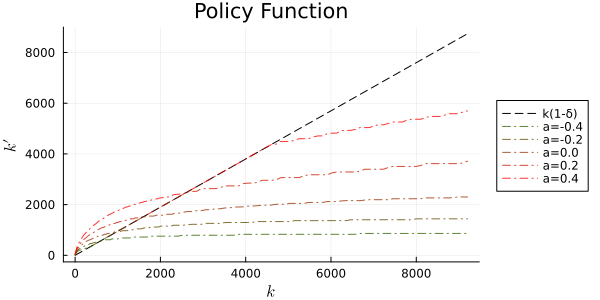

In [4]:
PolicyCalc.plot_policy(p, m)

# Simulation of Representative Agent Model

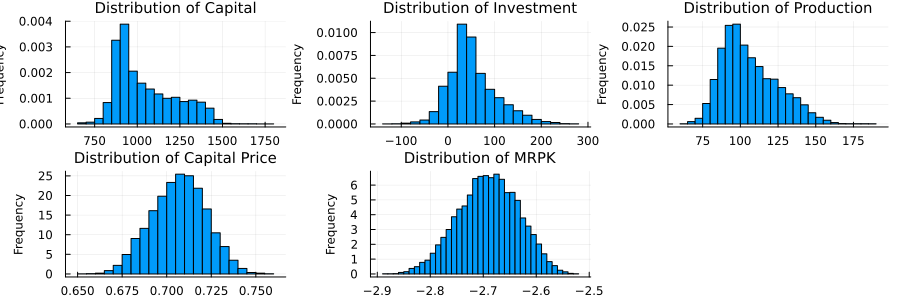

In [5]:
shocks_m = m.shocks_m_sim(10000, 1);
shocks_z = m.shocks_z_sim(10000, 2);
simulation_ts = SimulationTS.simulate_ts(m, p, shocks_z, shocks_m)
SimulationTS.plot_dist(simulation_ts)

# Simulation of Heterogeneous Agent Model

After simulating firms over time, total production, total capital, and total investment are obtained by aggregating the corresponding firm-level variables at each time period. Ad
ditionally, misallocation is quantified by calculating $\sigma^2_{mrpk}$ at each time step. To provide a more precise statistical analysis, the mean and standard deviation of these indicators are computed over time and reported in the following tables.

Run heterogeneous model for average common productivity equals to zero:

In [6]:
df0 = Heter.arsh_model()

Baseline is saved as csv


Row,Title,K_total,I_total,Y_total,Pₖ_var,MRPK_var
,String,Float64,Float64,Float64,Float64,Float64
1,value,4.74105e8,2.37e7,7.0456e6,0.00573903,0.123074
2,std,6.90403e7,1.29012e7,1.08579e6,0.000473887,0.00407948


Run heterogeneous model for a range of average common productivity:

In [7]:
df = Heter.arsh_models_m_bar();

m_bar=-0.5 is saved as csv
m_bar=-0.25 is saved as csv
m_bar=0.0 is saved as csv
m_bar=0.25 is saved as csv
m_bar=0.5 is saved as csv


# Save the result

In [8]:
mkpath(joinpath("..", "output"))
CSV.write(joinpath("..", "output", "DataFrames.csv"), df)

"DataFrames.csv"

# Plot the result

In [9]:
df

Row,Title,K_total,I_total,Y_total,Pₖ_var,MRPK_var
,String,Float64,Float64,Float64,Float64,Float64
1,value,2.2463e7,1.12287e6,5.50865e5,0.0193679,0.140186
2,std,3.82575e6,7.16707e5,93283.6,0.00213205,0.00885546
3,value,1.04139e8,5.20578e6,1.98256e6,0.0105325,0.131528
4,std,1.65585e7,3.02808e6,3.20547e5,0.00099852,0.00589048
5,value,4.74105e8,2.37e7,7.0456e6,0.00573903,0.123074
6,std,6.90403e7,1.29012e7,1.08579e6,0.000473887,0.00407948
7,value,2.0467e9,1.02314e8,2.42805e7,0.0031566,0.115072
8,std,2.72588e8,5.23474e7,3.56717e6,0.000241005,0.00362051
9,value,8.70159e9,4.34995e8,8.24979e7,0.00175879,0.107359


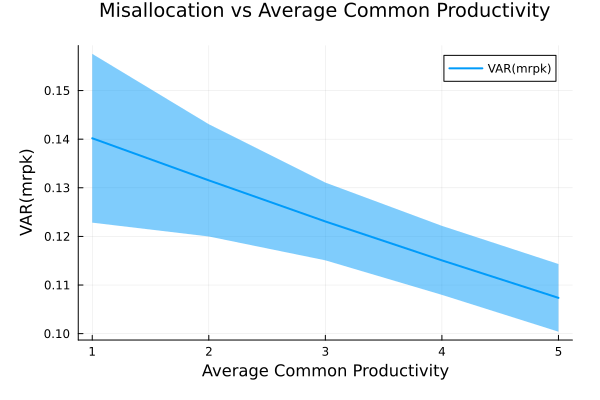

In [10]:
p = Heter.plot_mrpk(df)
display(p)

Misallocation metrics are computed across a spectrum of average common productivity values, as depicted in this figure. The baseline model suggests that in economies characterized
 by elevated levels of common productivity, misallocation tends to be reduced. This relationship implies that enhancements in macroeconomic productivity not only augment
 allocative efficiency but also contribute to production growth, driven by both heightened productivity levels and optimized resource allocation. $\blacksquare$

---
